<a href="https://colab.research.google.com/github/Calvin-Gacheru/african-wildlife-classification/blob/main/Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# African Wildlife Image Classification Pipeline

Implementing a two-stage transfer learning pipeline to classify the big five Wildllife species. We utilized **ResNet50 convolutional neural network** to evaluate the practical impacts of feature extraction.


## Step One: Import the Libraries, Load the Data

In [ ]:
import kagglehub
import os
import shutil
import time
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix


In [ ]:
# Download both datasets
print("Downloading African Wildlife dataset...")
wildlife_path = kagglehub.dataset_download("biancaferreira/african-wildlife")

print("Downloading Big Cats dataset...")
big_cats_path = kagglehub.dataset_download("patriciabrezeanu/big-cats-image-classification-dataset")

# Create a master directory for the final Big 5 dataset
target_dir = "./big_5_dataset"
if os.path.exists(target_dir):
  shutil.rmtree(target_dir)
os.makedirs(target_dir, exist_ok=True)

# Extract Buffalo, Elephant, and Rhino - Drop Zebra
print("Extracting Buffalo, Elephant, and Rhino...")
wildlife_classes = ['buffalo', 'elephant', 'rhino']

# Extract Lion and Leopard
print("Extracting Lion and Leopard...")
big_cats_base = os.path.join(big_cats_path, 'animals')
cat_classes = ['lion', 'leopard']

for cat in cat_classes:
  src = os.path.join(big_cats_base, cat)
  dest = os.path.join(target_dir, cat)
  if os.path.exists(src):
    shutil.copytree(src, dest)
    print(f" - Added {cat}")


for root, dirs, files in os.walk(wildlife_path):
    for d in dirs:
        if d.lower() in wildlife_classes:
            src = os.path.join(root, d)
            dest = os.path.join(target_dir, d.lower())
            if not os.path.exists(dest):
                shutil.copytree(src, dest)
                print(f" - Added {d.lower()}")

print(f"\nMerge complete! target directory: {target_dir}")
print("Final Classes:", os.listdir(target_dir))

100%|██████████| 448M/448M [00:06<00:00, 71.3MB/s]

Extracting files...


100%|██████████| 508M/508M [00:03<00:00, 134MB/s]

Extracting files...


Extracting Buffalo, Elephant, and Rhino...
Extracting Lion and Leopard...
 - Added lion
 - Added leopard
 - Added elephant
 - Added buffalo
 - Added rhino

Merge complete! target directory: ./big_5_dataset
Final Classes: ['elephant', 'buffalo', 'leopard', 'rhino', 'lion']


## Step Two: Data pipelines
- Loading the Images
- Splitting the images 70/15/15
- Standardizing the dimensions (224x224 for ResNet50)
- Adding augumentation layes

In [ ]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224) # For ResNet50
DATA_DIR = './big_5_dataset'

# Extract 70% for training
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = train_ds.class_names
print("Classes detected:", class_names)

Found 1484 files belonging to 5 classes.
Using 1039 files for training.
Classes detected: ['buffalo', 'elephant', 'leopard', 'lion', 'rhino']


In [ ]:
# Extract 30% for Validation/Testing pool
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 1484 files belonging to 5 classes.
Using 445 files for validation.


In [ ]:
# Split the 30% pool in half (155 Validation, 15% test)
val_batches = tf.data.experimental.cardinality(val_test_ds)
val_ds = val_test_ds.take(val_batches // 2)
test_ds = val_test_ds.skip(val_batches // 2)

In [ ]:
# Define Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

# Apply augmentations to training data and optimize memory
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Data pipeline complete")

Data pipeline complete


## Step Three: Model Construction

Here we will build the neural network. We are using ResNet50 as the backbone. In this step we will:

- Load ResNet50: download the version of ResNet50 that has already been training onmillions of images (weights='imagenet')
- Freeze it: Lock the weights (base_model.trainable = False) so we don't erase it.
- Attach a Custom head: Attach a custom layer, ending with a 5-class output for the specific African wildlife.

In [ ]:
# Instantiate the core backbone
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the base parameters
base_model.trainable = False

# Attach the custom classificatin head
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(5, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 525,829 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

`Resnet50` layer takes a 224x224 image and processes it into a 7x7 grid with a depth of 2048 feature maps.

### Experiment A: Feature Extraction
This trains only the newly added custom classification head while teh ResNet50 backbone remains frozen.
- Compile the model with the Adam optimizer and a learning rate of 1e-3.
- Train for 10 epochs.
- Calculate the average time per epoch.

In [ ]:

# Callback to track training time for the required Results Matrix
class TimeHistory(tf.keras.callbacks.Callback):
  def on_train_begin(self, logs={}):
    self.times = []
  def on_epoch_begin(self, batch, logs={}):
    self.epoch_time_start = time.time()
  def on_epoch_end(self, batch, logs={}):
    self.times.append(time.time() - self.epoch_time_start)

time_callback_A = TimeHistory()

# Compile Experiment
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train Experiment
history_a = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[time_callback_A]
)

avg_time_a = sum(time_callback_A.times) / len(time_callback_A.times)
print(f"Average time per epoch: {avg_time_a:.2f} seconds")

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 43s 821ms/step - accuracy: 0.7218 - loss: 0.8738 - val_accuracy: 0.9688 - val_loss: 0.1213
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 25s 598ms/step - accuracy: 0.8864 - loss: 0.3277 - val_accuracy: 0.9420 - val_loss: 0.1397
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 629ms/step - accuracy: 0.9143 - loss: 0.2652 - val_accuracy: 0.9598 - val_loss: 0.1216
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 41s 631ms/step - accuracy: 0.9220 - loss: 0.2143 - val_accuracy: 0.9330 - val_loss: 0.1920
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 40s 604ms/step - accuracy: 0.9220 - loss: 0.1933 - val_accuracy: 0.9464 - val_loss: 0.1805
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 635ms/step - accuracy: 0.9259 - loss: 0.1866 - val_accuracy: 0.9598 - val_loss: 0.1457
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 606ms/step - accuracy: 0.9471 - loss: 0.1413 - val_accuracy: 0.9420 - val_loss: 0.1503
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 628ms/step - accuracy: 0.9432 - loss: 0.1410 - val_accu

Model Evaluation of Experiment A: Feature Extraction

In [12]:
y_true_A, y_pred_A = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred_A.extend(np.argmax(preds, axis=1))
    y_true_A.extend(np.argmax(labels.numpy(), axis=1))

print("\nExperiment A Classification Report:")
report_a = classification_report(y_true_A, y_pred_A, target_names=class_names, output_dict=True)
print(classification_report(y_true_A, y_pred_A, target_names=class_names))
print(f"Exp A Best Validation Accuracy: {max(history_a.history['val_accuracy'])*100:.2f}%")
print(f"Exp A Test Set Macro F1-Score: {report_a['macro avg']['f1-score']:.2f}")


Experiment A Classification Report:
              precision    recall  f1-score   support

     buffalo       0.92      0.90      0.91        51
    elephant       0.98      0.95      0.97        62
     leopard       0.96      1.00      0.98        25
        lion       1.00      0.95      0.98        21
       rhino       0.91      0.95      0.93        62

    accuracy                           0.95       221
   macro avg       0.95      0.95      0.95       221
weighted avg       0.95      0.95      0.95       221

Exp A Best Validation Accuracy: 96.88%
Exp A Test Set Macro F1-Score: 0.95


### Experiment B: Fine_Tuning


In [13]:
# Unfreeze the base model
base_model.trainable = True

# Freeze the lower layers (ResNet50 has 175 layers total)
for layer in base_model.layers[:143]:
    layer.trainable = False

time_callback_B = TimeHistory()

# Re-compile with conservative learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train Experiment B
history_b = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[time_callback_B]
)

avg_time_b = sum(time_callback_B.times) / len(time_callback_B.times)
print(f"\nExperiment B Average Epoch Time: {avg_time_b:.2f} seconds")

Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 54s 955ms/step - accuracy: 0.8874 - loss: 0.3253 - val_accuracy: 0.9241 - val_loss: 0.2446
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 611ms/step - accuracy: 0.9432 - loss: 0.1755 - val_accuracy: 0.9375 - val_loss: 0.1530
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 661ms/step - accuracy: 0.9528 - loss: 0.1333 - val_accuracy: 0.9241 - val_loss: 0.2279
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 621ms/step - accuracy: 0.9644 - loss: 0.1062 - val_accuracy: 0.9554 - val_loss: 0.1383
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 42s 637ms/step - accuracy: 0.9711 - loss: 0.0894 - val_accuracy: 0.9420 - val_loss: 0.1570
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 642ms/step - accuracy: 0.9721 - loss: 0.0886 - val_accuracy: 0.9598 - val_loss: 0.1353
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 594ms/step - accuracy: 0.9808 - loss: 0.0620 - val_accuracy: 0.9688 - val_loss: 0.0861
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 647ms/step - accuracy: 0.9798 - loss: 0.0644 - val_accu

Model Evaluation of Experiment B: Fine Tuning

In [14]:
y_true_B, y_pred_B = [], []
for images, labels in test_ds:
  preds = model.predict(images, verbose=0)
  y_pred_B.extend(np.argmax(preds, axis=1))
  y_true_B.extend(np.argmax(labels.numpy(), axis=1))

print("\nExperiment B Classification Report:")
report_b = classification_report(y_true_B, y_pred_B, target_names=class_names, output_dict=True)
print(classification_report(y_true_B, y_pred_B, target_names=class_names))
print(f"Exp B Best Validation Accuracy: {max(history_b.history['val_accuracy'])*100:.2f}%")
print(f"Exp B Test Set Macro F1-Score: {report_b['macro avg']['f1-score']:.2f}")


Experiment B Classification Report:
              precision    recall  f1-score   support

     buffalo       0.94      0.88      0.91        51
    elephant       0.98      0.98      0.98        58
     leopard       0.96      0.96      0.96        24
        lion       0.92      0.92      0.92        26
       rhino       0.92      0.97      0.94        62

    accuracy                           0.95       221
   macro avg       0.94      0.94      0.94       221
weighted avg       0.95      0.95      0.95       221

Exp B Best Validation Accuracy: 97.77%
Exp B Test Set Macro F1-Score: 0.94


## Step Four: Evaluation Matrix

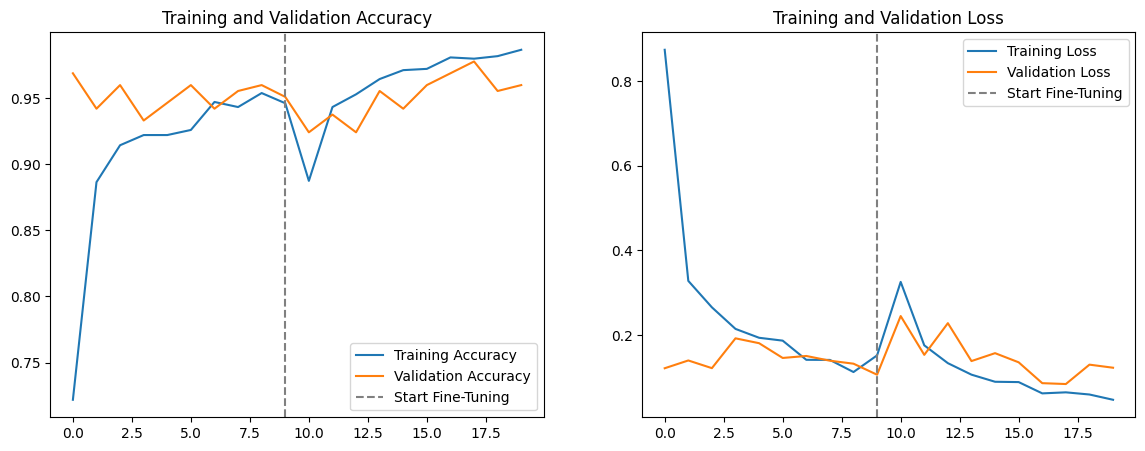

In [15]:
# Combine Histories for Continuous Plotting
acc = history_a.history['accuracy'] + history_b.history['accuracy']
val_acc = history_a.history['val_accuracy'] + history_b.history['val_accuracy']
loss = history_a.history['loss'] + history_b.history['loss']
val_loss = history_a.history['val_loss'] + history_b.history['val_loss']

# Plot Accuracy and Loss spanning both experiments
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_a.history['accuracy'])-1, color='gray', linestyle='--', label='Start Fine-Tuning')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history_a.history['loss'])-1, color='gray', linestyle='--', label='Start Fine-Tuning')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

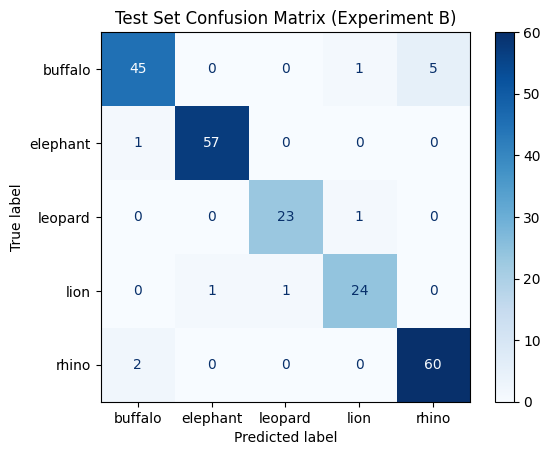

In [16]:
# Generate Confusion Matrix for the final model (Experiment B)
cm = confusion_matrix(y_true_B, y_pred_B)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Test Set Confusion Matrix (Experiment B)")
plt.show()

- Buffalo vs. Rhino: This is the model's biggest weakness. It mistook 3 actual buffaloes for rhinos, and mistook 2 actual rhinos for buffaloes.   
- The Big Cats: It confused 1 actual leopard for a lion, and 1 actual lion for a leopard.   
- Elephants: It is highly accurate here, correctly identifying 57 out of 58 elephants. It only missed 1, mistaking it for a buffalo.   
- False Elephants: The model falsely predicted "elephant" three times, incorrectly applying the label to 1 buffalo, 1 lion, and 1 rhino.

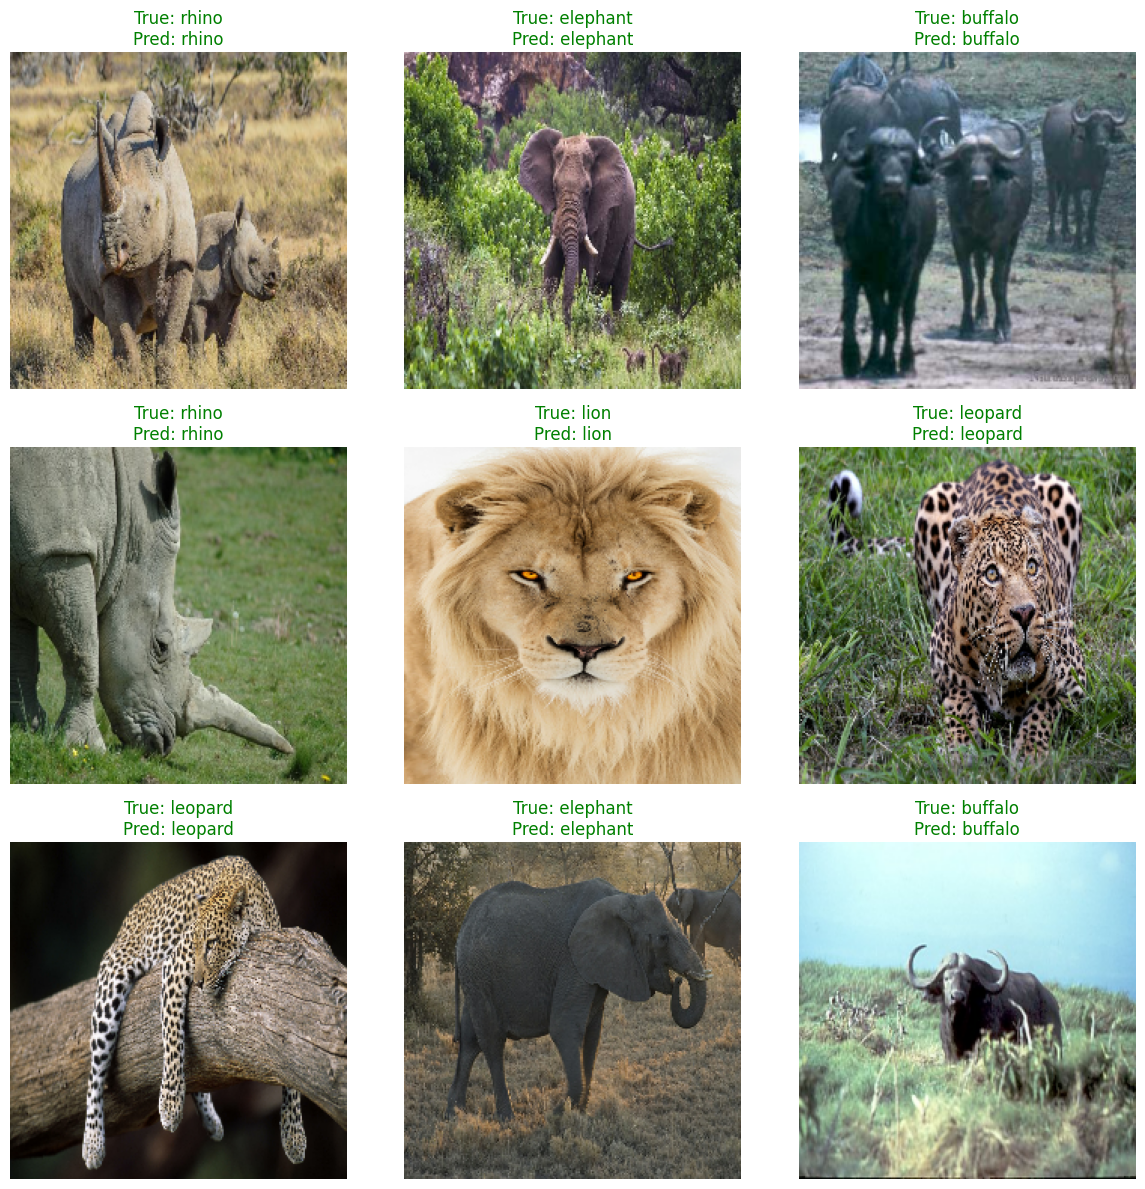

In [17]:
# Take a single batch of unseen images from the test dataset
for images, labels in test_ds.take(1):
    # Run the model predictions
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 12))

    # Plot the first 9 images in the batch
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        # Convert image tensor to displayable format
        plt.imshow(images[i].numpy().astype("uint8"))

        # Extract the text labels
        actual_class = class_names[np.argmax(labels[i])]
        predicted_class = class_names[np.argmax(predictions[i])]

        # Assign color based on accuracy
        text_color = "green" if actual_class == predicted_class else "red"

        plt.title(f"True: {actual_class}\nPred: {predicted_class}", color=text_color)
        plt.axis("off")

    plt.tight_layout()
    plt.show()